In [22]:
import sys
import os

project_root = os.path.abspath("..")
sys.path.append(project_root)

In [23]:
"""Multi-agent supervisor for coordinating research across multiple specialized agents.

This module implements a supervisor pattern where:
1. A supervisor agent coordinates research activities and delegates tasks
2. Multiple researcher agents work on specific sub-topics independently
3. Results are aggregated and compressed for final reporting

The supervisor uses parallel research execution to improve efficiency while
maintaining isolated context windows for each research topic.
"""

import asyncio
import importlib

from typing_extensions import Literal

from langchain_core.messages import (
    HumanMessage, 
    BaseMessage, 
    SystemMessage, 
    ToolMessage,
    filter_messages
)
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from langchain_google_genai import ChatGoogleGenerativeAI

# Reload modules to clear any cached imports in the notebook kernel
import deep_research.state
import deep_research.utils
import deep_research.agents
importlib.reload(deep_research.state)
importlib.reload(deep_research.utils)
importlib.reload(deep_research.agents)

from deep_research.prompt import lead_researcher_prompt
from deep_research.agents import researcher_agent
from deep_research.state import SupervisorState, ConductResearch, ResearchComplete

from deep_research.utils import get_today_str, think_tool

In [24]:
# Ensure async compatibility for Jupyter environments
try:
    import nest_asyncio
    # Only apply if running in Jupyter/IPython environment
    try:
        from IPython import get_ipython
        if get_ipython() is not None:
            nest_asyncio.apply()
    except ImportError:
        pass  # Not in Jupyter, no need for nest_asyncio
except ImportError:
    pass  # nest_asyncio not available, proceed without it

In [25]:
def get_notes_from_tool_calls(messages: list[BaseMessage]) -> list[str]:
    """Extract research notes from ToolMessage objects in supervisor message history.
    
    This function retrieves the compressed research findings that sub-agents
    return as ToolMessage content. When the supervisor delegates research to
    sub-agents via ConductResearch tool calls, each sub-agent returns its
    compressed findings as the content of a ToolMessage. This function
    extracts all such ToolMessage content to compile the final research notes.
    
    Args:
        messages: List of messages from supervisor's conversation history
        
    Returns:
        List of research note strings extracted from ToolMessage objects
    """
    return [tool_msg.content for tool_msg in filter_messages(messages, include_types="tool")]

In [26]:
supervisor_tools = [ConductResearch, ResearchComplete, think_tool]

supervisor_model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.7,
    max_tokens=32000,
    timeout=None,
)
supervisor_model_with_tools = supervisor_model.bind_tools(supervisor_tools)

In [27]:
# System constants

# Maximum number of tool call iterations for individual researcher agents
# This prevents infinite loops and controls research depth per topic
max_researcher_iterations = 6 # Calls to think_tool + ConductResearch

# Maximum number of concurrent research agents the supervisor can launch
# This is passed to the lead_researcher_prompt to limit parallel research tasks
max_concurrent_researchers = 3

In [28]:
async def supervisor(state: SupervisorState) -> Command[Literal["supervisor_tools"]]:
    """Coordinate research activities.
    
    Analyzes the research brief and current progress to decide:
    - What research topics need investigation
    - Whether to conduct parallel research
    - When research is complete
    
    Args:
        state: Current supervisor state with messages and research progress
        
    Returns:
        Command to proceed to supervisor_tools node with updated state
    """
    supervisor_messages = state.get("supervisor_messages", [])
    
    # Prepare system message with current date and constraints
    system_message = lead_researcher_prompt.format(
        date=get_today_str(), 
        max_concurrent_research_units=max_concurrent_researchers,
        max_researcher_iterations=max_researcher_iterations
    )
    messages = [SystemMessage(content=system_message)] + supervisor_messages
    
    # Make decision about next research steps
    response = await supervisor_model_with_tools.ainvoke(messages)
    
    return Command(
        goto="supervisor_tools",
        update={
            "supervisor_messages": [response],
            "research_iterations": state.get("research_iterations", 0) + 1
        }
    )

In [29]:
async def supervisor_tools(state: SupervisorState) -> Command[Literal["supervisor", "__end__"]]:
    """Execute supervisor decisions - either conduct research or end the process.
    
    Handles:
    - Executing think_tool calls for strategic reflection
    - Launching parallel research agents for different topics
    - Aggregating research results
    - Determining when research is complete
    
    Args:
        state: Current supervisor state with messages and iteration count
        
    Returns:
        Command to continue supervision, end process, or handle errors
    """
    supervisor_messages = state.get("supervisor_messages", [])
    research_iterations = state.get("research_iterations", 0)
    most_recent_message = supervisor_messages[-1]
    
    # Initialize variables for single return pattern
    tool_messages = []
    all_raw_notes = []
    next_step = "supervisor"  # Default next step
    should_end = False
    
    # Check exit criteria first
    exceeded_iterations = research_iterations >= max_researcher_iterations
    no_tool_calls = not most_recent_message.tool_calls
    research_complete = any(
        tool_call["name"] == "ResearchComplete" 
        for tool_call in most_recent_message.tool_calls
    )
    
    if exceeded_iterations or no_tool_calls or research_complete:
        should_end = True
        next_step = END
    else:
        # Execute ALL tool calls before deciding next step
        try:
            # Separate think_tool calls from ConductResearch calls
            think_tool_calls = [
                tool_call for tool_call in most_recent_message.tool_calls 
                if tool_call["name"] == "think_tool"
            ]
            
            conduct_research_calls = [
                tool_call for tool_call in most_recent_message.tool_calls 
                if tool_call["name"] == "ConductResearch"
            ]

            # Handle think_tool calls (synchronous)
            for tool_call in think_tool_calls:
                observation = think_tool.invoke(tool_call["args"])
                tool_messages.append(
                    ToolMessage(
                        content=observation,
                        name=tool_call["name"],
                        tool_call_id=tool_call["id"]
                    )
                )

            # Handle ConductResearch calls (asynchronous)
            if conduct_research_calls:
                # Launch parallel research agents
                coros = [
                    researcher_agent.ainvoke({
                        "researcher_messages": [
                            HumanMessage(content=tool_call["args"]["research_topic"])
                        ],
                        "research_topic": tool_call["args"]["research_topic"]
                    }) 
                    for tool_call in conduct_research_calls
                ]

                # Wait for all research to complete
                tool_results = await asyncio.gather(*coros)

                # Format research results as tool messages
                # Each sub-agent returns compressed research findings in result["compressed_research"]
                # We write this compressed research as the content of a ToolMessage, which allows
                # the supervisor to later retrieve these findings via get_notes_from_tool_calls()
                research_tool_messages = [
                    ToolMessage(
                        content=result.get("compressed_research", "Error synthesizing research report"),
                        name=tool_call["name"],
                        tool_call_id=tool_call["id"]
                    ) for result, tool_call in zip(tool_results, conduct_research_calls)
                ]
                
                tool_messages.extend(research_tool_messages)

                # Aggregate raw notes from all research
                all_raw_notes = [
                    "\n".join(result.get("raw_notes", [])) 
                    for result in tool_results
                ]
                
        except Exception as e:
            print(f"Error in supervisor tools: {e}")
            should_end = True
            next_step = END
    
    # Single return point with appropriate state updates
    if should_end:
        return Command(
            goto=next_step,
            update={
                "notes": get_notes_from_tool_calls(supervisor_messages),
                "research_brief": state.get("research_brief", "")
            }
        )
    else:
        return Command(
            goto=next_step,
            update={
                "supervisor_messages": tool_messages,
                "raw_notes": all_raw_notes
            }
        )

In [30]:
supervisor_builder = StateGraph(SupervisorState)
supervisor_builder.add_node("supervisor", supervisor)
supervisor_builder.add_node("supervisor_tools", supervisor_tools)
supervisor_builder.add_edge(START, "supervisor")
supervisor_agent = supervisor_builder.compile()

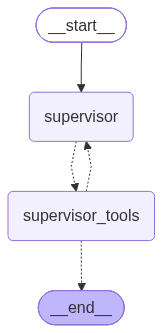

In [31]:
from IPython.display import Image, display

# Show the agent
display(Image(supervisor_agent.get_graph(xray=True).draw_mermaid_png()))


In [33]:
from utils import format_messages
from langchain_core.messages import HumanMessage

research_brief = """I want to determine the best Indian Premier League (IPL) team by analyzing two primary metrics: the total number of championship trophies won and the overall win percentage. 
Please research all IPL teams, including defunct ones, from the league's inception in 2008 to the most recently completed season. 
The final output should be a comparative analysis that ranks or lists all teams based on both their total number of IPL titles and their all-time win percentage. 
Please use official sources like the IPL's official website (iplt20.com) or highly reputable sports statistics sites like ESPNcricinfo for data."""

result = await supervisor_agent.ainvoke({"supervisor_messages": [HumanMessage(content=f"{research_brief}.")]})
format_messages(result['supervisor_messages'])

d:\DeepResearchAgent\DeepResearchAgent\.venv\lib\site-packages\langchain_google_genai\chat_models.py:3120: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\DeepResearchAgent\DeepResearchAgent\.venv\lib\site-packages\langchain_google_genai\chat_models.py:3120: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
d:\DeepResearchAgent\DeepResearchAgent\.venv\lib\site-packages\langchain_google_genai\chat_models.py:3120: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
d:\DeepResearchAgent\DeepResearchAgent\.venv\lib\s

Error in supervisor tools: Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash\nPlease retry in 11.063655201s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTie

╭─────────────────────────────────────────────────── 🧑 Human ────────────────────────────────────────────────────╮
│ I want to determine the best Indian Premier League (IPL) team by analyzing two primary metrics: the total       │
│ number of championship trophies won and the overall win percentage.                                             │
│ Please research all IPL teams, including defunct ones, from the league's inception in 2008 to the most recently │
│ completed season.                                                                                               │
│ The final output should be a comparative analysis that ranks or lists all teams based on both their total       │
│ number of IPL titles and their all-time win percentage.                                                         │
│ Please use official sources like the IPL's official website (iplt20.com) or highly reputable sports statistics  │
│ sites like ESPNcricinfo for data..                                                                              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│ 🔧 Tool Call: think_tool                                                                                        │
│    Args: {                                                                                                      │
│   "reflection": "The user wants a comprehensive analysis ranking all IPL teams (active and defunct) from 2008   │
│ through the most recently completed season (IPL 2026 / recent IPL seasons) based on two primary metrics:\n1.    │
│ Total IPL championship titles won\n2. Overall win percentage (all-time matches played, won, lost, tied/no       │
│ result, win percentage)\n\nTo gather this data accurately:\nI need to query ESPNcricinfo / IPL official stats   │
│ for:\n- List of all IPL champions year-by-year from 2008 to 2026, summarizing titles per team.\n- Complete      │
│ all-time team records in IPL (Matches played, won, lost, tied, no result, win percentage) for all teams         │
│ including defunct ones (Deccan Chargers, Kochi Tuskers Kerala, Pune Warriors India, Gujarat Lions, Rising Pune  │
│ Supergiant, etc., as well as active ones: CSK, MI, KKR, SRH, RR, RCB, DC, PBKS/KXIP, LSG, GT).\n\nSince this is │
│ a straightforward statistical query covering all IPL teams and their overall records, I can delegate this       │
│ research topic to a single comprehensive research task.\n\nLet's do a single ConductResearch call targeting     │
│ overall IPL team records (titles and win percentage up to 2026)."                                               │
│ }                                                                                                               │
│    ID: call_2529487                                                                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Reflection recorded: The user wants a comprehensive analysis ranking all IPL teams (active and defunct) from    │
│ 2008 through the most recently completed season (IPL 2026 / recent IPL seasons) based on two primary metrics:   │
│ 1. Total IPL championship titles won                                                                            │
│ 2. Overall win percentage (all-time matches played, won, lost, tied/no result, win percentage)                  │
│                                                                                                                 │
│ To gather this data accurately:                                                                                 │
│ I need to query ESPNcricinfo / IPL official stats for:                                                          │
│ - List of all IPL champions year-by-year from 2008 to 2026, summarizing titles per team.                        │
│ - Complete all-time team records in IPL (Matches played, won, lost, tied, no result, win percentage) for all    │
│ teams including defunct ones (Deccan Chargers, Kochi Tuskers Kerala, Pune Warriors India, Gujarat Lions, Rising │
│ Pune Supergiant, etc., as well as active ones: CSK, MI, KKR, SRH, RR, RCB, DC, PBKS/KXIP, LSG, GT).             │
│                                                                                                                 │
│ Since this is a straightforward statistical query covering all IPL teams and their overall records, I can       │
│ delegate this research topic to a single comprehensive research task.                                           │
│                                                                                                                 │
│ Let's do a single ConductResearch call targeting overall IPL team records (titles and win percentage up to      │
│ 2026).                                                                                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│ 🔧 Tool Call: ConductResearch                                                                                   │
│    Args: {                                                                                                      │
│   "research_topic": "Complete all-time statistics for all Indian Premier League (IPL) teams from 2008 to 2026,  │
│ including total IPL titles won by each team and overall match records (played, won, lost, tied, no result, and  │
│ win percentage) for all active and defunct teams (Chennai Super Kings, Mumbai Indians, Kolkata Knight Riders,   │
│ Sunrisers Hyderabad, Rajasthan Royals, Royal Challengers Bengaluru, Delhi Capitals/Daredevils, Punjab           │
│ Kings/Kings XI Punjab, Lucknow Super Giants, Gujarat Titans, Deccan Chargers, Kochi Tuskers Kerala, Pune        │
│ Warriors India, Gujarat Lions, Rising Pune Supergiant)."                                                        │
│ }                                                                                                               │
│    ID: call_2207845                                                                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ **List of Queries and Tool Calls Made**                                                                         │
│                                                                                                                 │
│ 1. `tavily_search`: `IPL all time team stats played won lost tied no result win percentage ESPNcricinfo`        │
│ 2. `think_tool`                                                                                                 │
│ 3. `tavily_search`: `site:wikipedia.org "Indian Premier League" "Team performance summary" OR "Result summary"  │
│ "Played" "Won" "Lost" "Tie"`                                                                                    │
│ 4. `tavily_search`: `"Chennai Super Kings" "Mumbai Indians" "Kolkata Knight Riders" "Played" "Won" "Lost"       │
│ "Tied" "No Result" "Win %" IPL records summary`                                                                 │
│ 5. `think_tool`                                                                                                 │
│ 6. `tavily_search`: `"Kochi Tuskers Kerala" "Rising Pune Supergiant" "Pune Warriors India" "Deccan Chargers"    │
│ "Gujarat Lions" IPL played won lost tied win percentage`                                                        │
│ 7. `tavily_search`: `site:cricinfo.com "team-results-summary/indian-premier-league" OR ("Indian Premier League" │
│ "Span" "Mat" "Won" "Lost" "Tied")`                                                                              │
│ 8. `tavily_search`: `"Chennai Super Kings" "Mumbai Indians" "Kolkata Knight Riders" "Royal Challengers" "Punjab │
│ Kings" "Delhi Capitals" "Rajasthan Royals" "Sunrisers Hyderabad" "Lucknow Super Giants" "Gujarat Titans" IPL    │
│ overall record played won lost win percentage`                                                                  │
│ 9. `tavily_search`: `"Kochi Tuskers Kerala" "14" "6" "8" OR "Rising Pune Supergiant" "30" "15" "15" OR "Deccan  │
│ Chargers" "75" "29" "46" IPL stats`                                                                             │
│ 10. `tavily_search`: `site:overgraph.in/teams OR "overgraph.in" "Mumbai Indians" "Chennai Super Kings" "Played" │
│ "Wins" "Win %"`                                                                                                 │
│ 11. `tavily_search`: `"Rising Pune Supergiant" "30" "15" "15" OR "Gujarat Lions" "30" "13" "16" OR "Pune        │
│ Warriors" "46" "12" "33" OR "Deccan Chargers" "75" "29" "46" OR "Kochi Tuskers Kerala" "14" "6" "8"`            │
│                                                                                                                 │
│ ---                                                                                                             │
│                                                                                                                 │
│ **Fully Comprehensive Findings**                                                                                │
│                                                                                                                 │
│ ### 1. General Overview of the Indian Premier League (IPL)                                                      │
│ - **Establishment and Structure**: Founded in 2007/2008 by the Board of Control for Cricket in India (BCCI),    │
│ the Indian Premier League (IPL) is an annual domestic Twenty20 cricket tournament featuring city-based          │
│ franchise teams [1], [2]. Since 2022, ten active teams compete in the league [2].                               │
│ - **Format Evolution**: In various seasons (including 2022–2026), teams have been divided into two groups of    │
│ five teams determined by draws or title counts [1], [2], [3].                                                   │
│ - **2026 Group Allocation**:                           

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│ 🔧 Tool Call: think_tool                                                                                        │
│    Args: {                                                                                                      │
│   "reflection": "Let's assess what we have:\n1. Champion Titles:\n- Chennai Super Kings (CSK): 5 titles (2010,  │
│ 2011, 2018, 2021, 2023)\n- Mumbai Indians (MI): 5 titles (2013, 2015, 2017, 2019, 2020)\n- Kolkata Knight       │
│ Riders (KKR): 3 titles (2012, 2014, 2024)\n- Royal Challengers Bengaluru (RCB): 2 titles (2025, 2026) .\n-      │
│ Rajasthan Royals (RR): 1 title (2008)\n- Sunrisers Hyderabad (SRH): 1 title (2016)\n- Deccan Chargers (DC -     │
│ defunct): 1 title (2009)\n- Gujarat Titans (GT): 1 title (2022)\n- Delhi Capitals (DC), Punjab Kings (PBKS),    │
│ Lucknow Super Giants (LSG), Kochi Tuskers Kerala (KTK), Pune Warriors India (PWI), Gujarat Lions (GL), Rising   │
│ Pune Supergiant (RPS): 0 titles.\n\nLet's do a targeted query to ensure we have exact match statistics (Played, │
│ Won, Lost, Tied, No Result, Win %) for all 15 teams (both active and defunct) from official ESPNcricinfo / IPL  │
│ sources up to the latest completed season, so that the rankings by both metrics are completely comprehensive    │
│ and accurate down to every number.\n\nLet's conduct one more ConductResearch query specifically targeting the   │
│ exact table of IPL Team Overall Result Summary (Matches, Wins, Losses, Ties, No Results, Win %) from            │
│ ESPNcricinfo."                                                                                                  │
│ }                                                                                                               │
│    ID: call_1976169                                                                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Reflection recorded: Let's assess what we have:                                                                 │
│ 1. Champion Titles:                                                                                             │
│ - Chennai Super Kings (CSK): 5 titles (2010, 2011, 2018, 2021, 2023)                                            │
│ - Mumbai Indians (MI): 5 titles (2013, 2015, 2017, 2019, 2020)                                                  │
│ - Kolkata Knight Riders (KKR): 3 titles (2012, 2014, 2024)                                                      │
│ - Royal Challengers Bengaluru (RCB): 2 titles (2025, 2026) .                                                    │
│ - Rajasthan Royals (RR): 1 title (2008)                                                                         │
│ - Sunrisers Hyderabad (SRH): 1 title (2016)                                                                     │
│ - Deccan Chargers (DC - defunct): 1 title (2009)                                                                │
│ - Gujarat Titans (GT): 1 title (2022)                                                                           │
│ - Delhi Capitals (DC), Punjab Kings (PBKS), Lucknow Super Giants (LSG), Kochi Tuskers Kerala (KTK), Pune        │
│ Warriors India (PWI), Gujarat Lions (GL), Rising Pune Supergiant (RPS): 0 titles.                               │
│                                                                                                                 │
│ Let's do a targeted query to ensure we have exact match statistics (Played, Won, Lost, Tied, No Result, Win %)  │
│ for all 15 teams (both active and defunct) from official ESPNcricinfo / IPL sources up to the latest completed  │
│ season, so that the rankings by both metrics are completely comprehensive and accurate down to every number.    │
│                                                                                                                 │
│ Let's conduct one more ConductResearch query specifically targeting the exact table of IPL Team Overall Result  │
│ Summary (Matches, Wins, Losses, Ties, No Results, Win %) from ESPNcricinfo.                                     │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│ 🔧 Tool Call: ConductResearch                                                                                   │
│    Args: {                                                                                                      │
│   "research_topic": "Exact IPL team all-time result summary table from ESPNcricinfo or official IPL statistics: │
│ played, won, lost, tied, no result, and win percentage for all 15 IPL teams (Chennai Super Kings, Mumbai        │
│ Indians, Kolkata Knight Riders, Royal Challengers Bangalore/Bengaluru, Rajasthan Royals, Sunrisers Hyderabad,   │
│ Gujarat Titans, Delhi Capitals/Daredevils, Punjab Kings/Kings XI Punjab, Lucknow Super Giants, Deccan Chargers, │
│ Rising Pune Supergiant, Gujarat Lions, Pune Warriors India, Kochi Tuskers Kerala) up to the most recent         │
│ completed IPL season."                                                                                          │
│ }                                                                                                               │
│    ID: call_2290985                                                                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
from IPython.display import Markdown, display
from deep_research.prompt import final_report_generation_prompt

# 1. Display the full detailed research findings collected by the sub-agents
print("=== GATHERED RESEARCH FINDINGS ===")
notes = result.get("notes", [])
if not notes:
    # Extract from tool messages if notes list is empty
    notes = [
        m.content for m in result.get("supervisor_messages", [])
        if getattr(m, "name", "") == "ConductResearch"
    ]

for note in notes:
    display(Markdown(note))

# 2. Synthesize into the final comprehensive executive report
if notes:
    print("\n=== FINAL EXECUTIVE REPORT ===")
    report_prompt = final_report_generation_prompt.format(
        research_brief=research_brief,
        date=get_today_str(),
        findings="\n\n".join(notes)
    )
    final_report_response = await supervisor_model.ainvoke([HumanMessage(content=report_prompt)])
    content = final_report_response.content
    if isinstance(content, list):
        final_markdown = "\n".join(
            part.get("text", str(part)) if isinstance(part, dict) else getattr(part, "text", str(part))
            for part in content
        )
    else:
        final_markdown = str(content)
    display(Markdown(final_markdown))